# 👗 Smart Fashion AI with Neural Networks (Mid Term)

**Total Marks: 100 (Theory: 10 | Practical: 90)**  


---

**Instructions:**
1. Enter your course email in the cell below.
2. Read the story and problem descriptions carefully.
3. Complete the code in cells containing `# YOUR CODE HERE`. Do not modify the test cells.
4. Run all cells sequentially to ensure your tests pass before submitting.
5. Have fun!

In [57]:
# Enter your course email here
student_email = "saiyedul.abrar1430@gmail.com" # Example: "your.name@university.edu"
student_email

'saiyedul.abrar1430@gmail.com'

---

## 📖 Story: StyleAI — Smart Fashion Recognition

You've just joined **StyleAI**, a startup building an AI-powered wardrobe assistant app. The app lets users snap a photo of any clothing item and instantly classifies it. Your job is to build the **image classification model** that powers this feature.

The dataset is **Fashion-MNIST** — 28×28 grayscale images of 10 clothing categories:

| Label | Class Name |
|-------|------------|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |


---

## Question 1: Theory (10 Marks)

### Part A (3 Marks)
Explain the difference between **Sigmoid** and **ReLU** activation functions. Why is ReLU preferred in hidden layers of deep networks? What problem does Sigmoid cause during backpropagation in deep networks?

### Part B (4 Marks)
In the context of **Gradient Descent**:
- What is the difference between **Batch Gradient Descent**, **Stochastic Gradient Descent (SGD)**, and **Mini-batch Gradient Descent**?
- State one advantage and one disadvantage of each.
- Which type would you recommend for training on Fashion-MNIST (60,000 images), and why?

### Part C (3 Marks)
In our Fashion-MNIST problem (10 classes):
1. Why do we use `nn.CrossEntropyLoss` instead of `nn.BCELoss`?
2. Why should we **NOT** put `nn.Softmax` as the last layer when using `nn.CrossEntropyLoss`?
3. What does `loss.backward()` do?

*Double-click here to write your answers*

**Part A Answer:**
Sigmoid maps any real value to (0,1), so it is useful for probability binary outputs. ReLU keeps positive values and sets negative values to zero.

ReLU is preferred in hidden layers because it is simple and computationally cheap, has a non-saturating positive region, and usually gives healthier gradients than sigmoid.

Sigmoid saturates for large positive or negative inputs; its derivative becomes close to zero, so repeated multiplication through many layers causes very slow learning.


**Part B Answer:**
Batch Gradient Descent: computes one gradient using all 60,000 training images before each parameter update. Advantage: stable, low-noise updates. Disadvantage: expensive memory/computation per update and slow feedback on a large dataset.

Stochastic Gradient Descent (SGD): computes an update from one image at a time. Advantage: frequent updates and low memory use, noise can help escape poor regions. Disadvantage: noisy, unstable loss trajectory and inefficient vectorization.

Mini-batch Gradient Descent: computes each update from a small batch, such as 32 or 64 images. Advantage: balances stable gradients, GPU/vectorization efficiency, and manageable memory. Disadvantage: batch size is another hyperparameter and the gradient still contains some noise.

For Fashion-MNIST I recommend Mini-batch Gradient Descent, typically with a batch size such as 64 or 128, because 60,000 images are too large for convenient full-batch updates while mini-batches use hardware efficiently and provide a good stability/speed compromise.


**Part C Answer:**
1. Fashion-MNIST is a single-label 10-class problem. nn.CrossEntropyLoss accepts one integer class index per image and combines LogSoftmax with negative log-likelihood loss in a numerically stable way. nn.BCELoss is for binary probabilities which is not a single 10-way class index.

2. The model should return raw logits. nn.CrossEntropyLoss applies the required log-softmax internally; adding nn.Softmax first is redundant and can reduce numerical stability and produce incorrect gradients.

3. loss.backward() traverses the computation graph in reverse using the chain rule and accumulates the gradient of the loss in each trainable parameter's .grad field. The optimizer then uses those gradients in optimizer.step() to update the parameters.



---

## Question 2: Load & Explore the Data (15 Marks)

### 2.1 Download the Dataset (1 Marks)

We will use `torchvision.datasets.FashionMNIST` to download the dataset. This is similar to how we loaded data from `.npy` files in class, but here PyTorch handles the download for us.

Run the cell below to download the training and test sets:

In [58]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import numpy as np
import matplotlib.pyplot as plt

# Class names for Fashion-MNIST
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Download Fashion-MNIST — this downloads the data into a ./data folder
# download=True means it will download if not already present
full_train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True)
test_dataset_raw = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True)

train_images_all = full_train_dataset.data.numpy()  # shape: (60000, 28, 28)
train_labels_all = full_train_dataset.targets.numpy()  # shape: (60000,)
test_images_all = test_dataset_raw.data.numpy()
test_labels_all = test_dataset_raw.targets.numpy()

print(f"Training set size: {len(full_train_dataset)}")
print(f"Test set size: {len(test_dataset_raw)}")
print(f"Image shape: {full_train_dataset[0][0].size}")

Training set size: 60000
Test set size: 10000
Image shape: (28, 28)


### 2.2 Visualize Sample Images (5 Marks)

Create a **2×5 subplot figure** (figsize 12×5) showing one sample image from **each of the 10 classes**.
- Display each image in grayscale (`cmap='gray'`)
- Title each subplot with its class name
- Turn off axis ticks

*Hint: loop through classes 0-9, find one sample of each class, and plot it.*

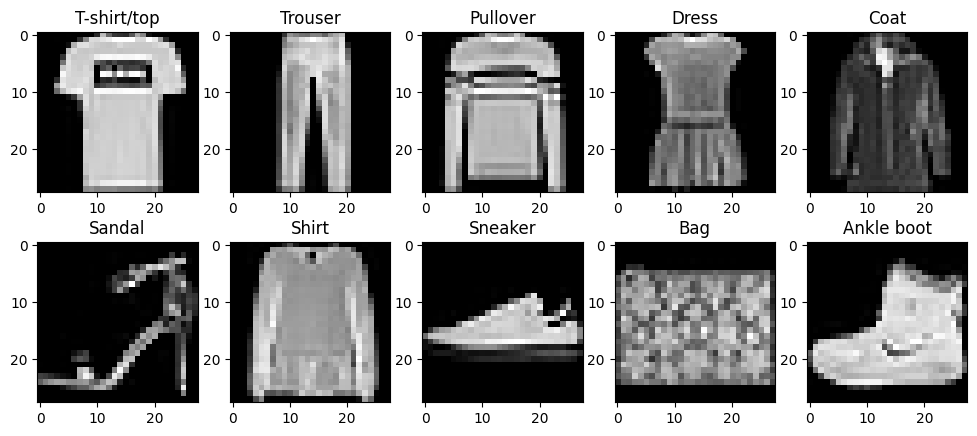

In [59]:
# YOUR CODE HERE

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(10):
    index = np.where(train_labels_all == i)[0][0]
    axes[i // 5, i % 5].imshow(train_images_all[index], cmap='gray')
    axes[i // 5, i % 5].set_title(class_names[i])

plt.show()

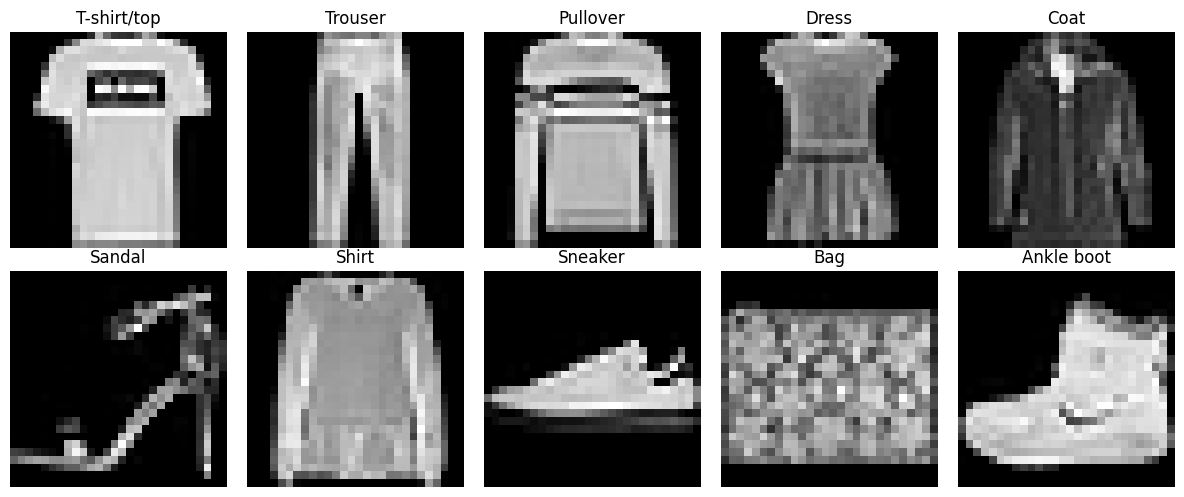

### 2.3 Class Distribution (5 Marks)

Plot a **bar chart** showing how many samples belong to each class in the training set.
- X-axis: class names
- Y-axis: count
- Title: "Training Set Class Distribution"
- Add the count number on top of each bar

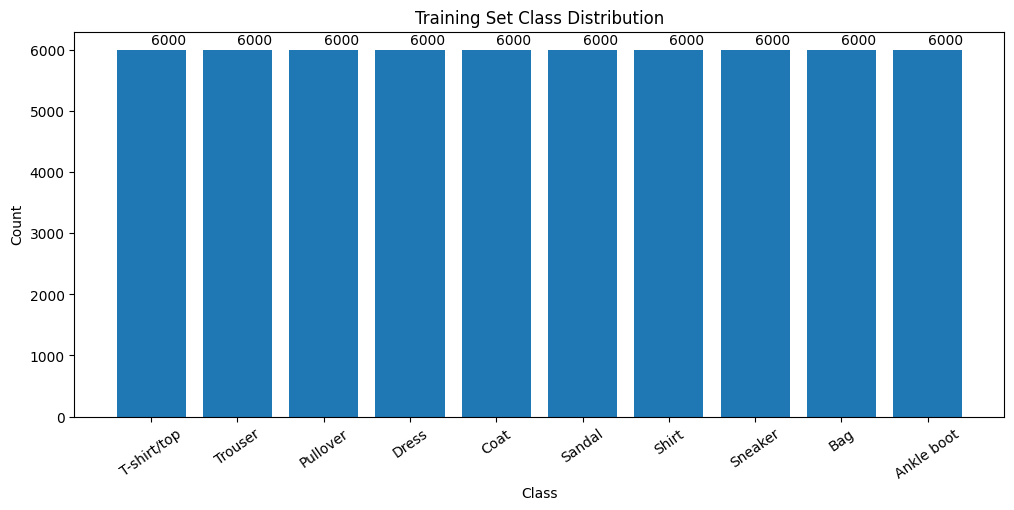

In [60]:
# YOUR CODE HERE

class_counts = []
for i in range(10):
    class_counts.append(np.sum(train_labels_all == i))

plt.figure(figsize=(12, 5))
bars = plt.bar(class_names, class_counts)
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Training Set Class Distribution')
plt.xticks(rotation=35)
for i in range(10):
    plt.text(i, class_counts[i] + 100, str(class_counts[i]))

plt.show()

### 2.4 Prepare Tensors and Split (4 Marks)

Now we need to extract the data as NumPy arrays, normalize it, split it, and convert to PyTorch tensors.



**Your tasks:**
1. Normalize pixel values to **[0, 1]** by dividing by 255.0.
2. Split training data into **train (50,000)** and **validation (10,000)** using `train_test_split` with `random_state=42`.
3. Convert all sets to PyTorch tensors — images as `float32`, labels as `long`.

**Required variables:** `X_train, X_val, X_test` (tensors), `y_train, y_val, y_test` (tensors)

In [61]:
from sklearn.model_selection import train_test_split

# YOUR CODE HERE

X = train_images_all / 255.0
X_test_numpy = test_images_all / 255.0
y = train_labels_all
y_test_numpy = test_labels_all

X_train_numpy, X_val_numpy, y_train_numpy, y_val_numpy = train_test_split(
    X, y, test_size=10000, random_state=42
)

X_train = torch.tensor(X_train_numpy, dtype=torch.float32)
X_val = torch.tensor(X_val_numpy, dtype=torch.float32)
X_test = torch.tensor(X_test_numpy, dtype=torch.float32)
y_train = torch.tensor(y_train_numpy, dtype=torch.long)
y_val = torch.tensor(y_val_numpy, dtype=torch.long)
y_test = torch.tensor(y_test_numpy, dtype=torch.long)

In [62]:
# --- TEST CELL (DO NOT MODIFY) ---
assert X_train.shape == (50000, 28, 28), f"Expected X_train shape (50000, 28, 28), got {X_train.shape}"
assert X_val.shape == (10000, 28, 28), f"Expected X_val shape (10000, 28, 28), got {X_val.shape}"
assert X_train.dtype == torch.float32, "X_train should be float32"
assert y_train.dtype == torch.long, "y_train should be long"
assert X_train.max() <= 1.0 and X_train.min() >= 0.0, "Pixel values should be in [0, 1]"
print("✅ Q2.4 Passed!")
print(f"   Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

✅ Q2.4 Passed!
   Train: torch.Size([50000, 28, 28]), Val: torch.Size([10000, 28, 28]), Test: torch.Size([10000, 28, 28])


---

## Question 3: Build DataLoaders (10 Marks)

Create `TensorDataset` and `DataLoader` objects for the train, validation, and test sets.

- **batch_size = 64**
- **shuffle = True** for training, **False** for validation and test

**Required variables:** `train_loader`, `val_loader`, `test_loader`

In [63]:
# YOUR CODE HERE

batch_size = 64

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [64]:
# --- TEST CELL (DO NOT MODIFY) ---
batch_X, batch_y = next(iter(train_loader))
assert batch_X.shape == (64, 28, 28), f"Batch shape should be (64, 28, 28), got {batch_X.shape}"
assert batch_y.dtype == torch.long, "Labels should be torch.long"
assert batch_X.max() <= 1.0, "Images should be normalized"
print("✅ Q3 Passed!")
print(f"   Batch images shape: {batch_X.shape}")
print(f"   Batch labels shape: {batch_y.shape}")

✅ Q3 Passed!
   Batch images shape: torch.Size([64, 28, 28])
   Batch labels shape: torch.Size([64])


---

## Question 4: Define the Model (15 Marks)

Create a class `FashionClassifier` inheriting from `nn.Module`.

Use `nn.Sequential` with this architecture:

| Layer | Description |
|-------|-------------|
| Flatten | Convert 28×28 → 784 |
| Linear | 784 → 256 |
| ReLU | Activation |
| Linear | 256 → 128 |
| ReLU | Activation |
| Linear | 128 → 64 |
| ReLU | Activation |
| Linear | 64 → 10 |

> **Note**: Do NOT apply Softmax at the output layer.

After defining the class:
1. Create an instance of `FashionClassifier`.
2. Print the model architecture.

In [65]:
# YOUR CODE HERE

class FashionClassifier(nn.Module):
  def __init__(self):
    super().__init__()
    self.network = nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 256),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
    )
  def forward(self, features):
    out = self.network(features)
    return out

model = FashionClassifier()
print(model)

FashionClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): ReLU()
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [66]:
# --- TEST CELL (DO NOT MODIFY) ---
test_input = torch.randn(5, 28, 28)
test_output = model(test_input)
assert test_output.shape == (5, 10), f"Output shape should be (5, 10), got {test_output.shape}"
total_params = sum(p.numel() for p in model.parameters())
assert total_params > 0, "Model should have trainable parameters"
print("✅ Q4 Passed!")
print(f"   Total parameters: {total_params}")
print(model)

✅ Q4 Passed!
   Total parameters: 242762
FashionClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): ReLU()
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


---

## Question 5: Train the Model (25 Marks)

### 5.1 Set Up Training (5 Marks)
- Loss function: `nn.CrossEntropyLoss`
- Optimizer: `optim.SGD` with `lr=0.01`
- Number of epochs: **15**

In [67]:
# YOUR CODE HERE

epochs = 15
loss_function = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

### 5.2 Training Loop (15 Marks)

Write a complete training loop for **15 epochs**.

For each epoch:
- Train on `train_loader` and compute training loss
- Evaluate on `val_loader` (with `torch.no_grad()`) and compute validation loss
- Print: `Epoch {epoch+1}/{epochs} | Train Loss: {:.4f} | Val Loss: {:.4f} `

Store: `train_losses`, `val_losses`, (lists, one value per epoch).

In [68]:
# YOUR CODE HERE

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []



for epoch in range(epochs):
  # Training
  model.train()
  train_loss = 0
  train_correct = 0
  for images, labels in train_loader:
    y_pred = model(images)
    loss = loss_function(y_pred, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss += loss.item()
    _, predicted = torch.max(y_pred.data, 1)
    train_correct += (predicted == labels).sum().item()

  train_loss = train_loss / len(train_loader)
  train_accuracy = 100 * train_correct / len(train_dataset)



  model.eval()
  val_loss = 0
  val_correct = 0
  with torch.no_grad():
    for images, labels in val_loader:
      y_pred = model(images)
      loss = loss_function(y_pred, labels)
      val_loss += loss.item()
      _, predicted = torch.max(y_pred.data, 1)
      val_correct += (predicted == labels).sum().item()

  val_loss = val_loss / len(val_loader)
  val_accuracy = 100 * val_correct / len(val_dataset)

  train_losses.append(train_loss)
  val_losses.append(val_loss)
  train_accuracies.append(train_accuracy)
  val_accuracies.append(val_accuracy)

  print(f'Epoch {epoch + 1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}')

Epoch 1/15 | Train Loss: 1.9404 | Val Loss: 1.2049
Epoch 2/15 | Train Loss: 0.9125 | Val Loss: 0.7773
Epoch 3/15 | Train Loss: 0.7069 | Val Loss: 0.7046
Epoch 4/15 | Train Loss: 0.6228 | Val Loss: 0.6640
Epoch 5/15 | Train Loss: 0.5751 | Val Loss: 0.5714
Epoch 6/15 | Train Loss: 0.5431 | Val Loss: 0.5403
Epoch 7/15 | Train Loss: 0.5175 | Val Loss: 0.5404
Epoch 8/15 | Train Loss: 0.4956 | Val Loss: 0.4944
Epoch 9/15 | Train Loss: 0.4759 | Val Loss: 0.7283
Epoch 10/15 | Train Loss: 0.4590 | Val Loss: 0.5031
Epoch 11/15 | Train Loss: 0.4442 | Val Loss: 0.4507
Epoch 12/15 | Train Loss: 0.4298 | Val Loss: 0.5431
Epoch 13/15 | Train Loss: 0.4177 | Val Loss: 0.4944
Epoch 14/15 | Train Loss: 0.4078 | Val Loss: 0.4628
Epoch 15/15 | Train Loss: 0.3989 | Val Loss: 0.4445


In [69]:
# --- TEST CELL (DO NOT MODIFY) ---
assert len(train_losses) == 15, f"Expected 15 epochs, got {len(train_losses)}"
assert len(val_losses) == 15
assert train_losses[-1] < train_losses[0], "Training loss should decrease"
print("✅ Q5.2 Passed!")
print(f"   Final Train Acc: {train_accuracies[-1]:.2f}%, Final Val Acc: {val_accuracies[-1]:.2f}%")

✅ Q5.2 Passed!
   Final Train Acc: 86.02%, Final Val Acc: 83.77%


### 5.3 Test Evaluation (5 Marks)

Evaluate the model on the **test set**. Print the test_accuracy (required_variable)

Also, collect all test predictions and true labels into lists called `all_preds` and `all_labels` (we'll use them for analysis later).

Print: `Test Accuracy: {:.2f}%`

In [70]:
# YOUR CODE HERE

model.eval()
all_preds= []
all_labels = []
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images)
        predictions = logits.argmax(dim=1)
        all_preds.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100.0 * correct / total
print(f'Test Accuracy: {test_accuracy:.2f}%')

Test Accuracy: 82.54%


In [71]:
# --- TEST CELL (DO NOT MODIFY) ---
assert test_accuracy > 40.0, f"Test accuracy should be > 40%, got {test_accuracy:.2f}%"
assert len(all_preds) == len(X_test), "Predictions should cover all test samples"
print(f"✅ Q5.3 Passed! Test Accuracy: {test_accuracy:.2f}%")

✅ Q5.3 Passed! Test Accuracy: 82.54%


---

## Question 6: Visualize & Analyze Results (25 Marks)

### 6.1 Plot Training Loss vs Validation Loss (5 Marks)

Plot **Training Loss** and **Validation Loss** on the same figure across epochs.
- Include a legend, title ("Loss Curve"), and axis labels.

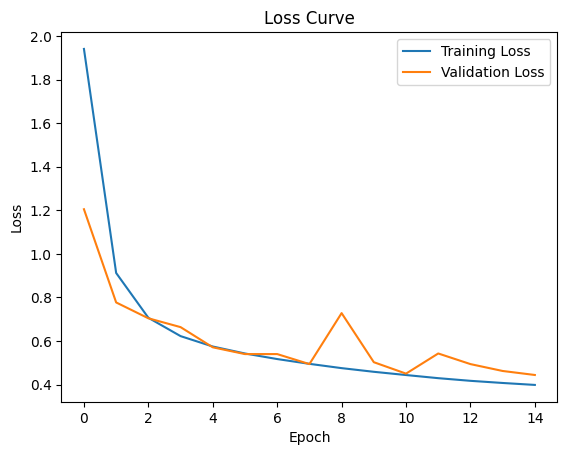

In [72]:
# YOUR CODE HERE

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curve')

plt.show()

### 6.2 Plot Training Accuracy vs Validation Accuracy (5 Marks)

Plot **Training Accuracy** and **Validation Accuracy** on the same figure across epochs.
- Include a legend, title ("Accuracy Curve"), and axis labels.

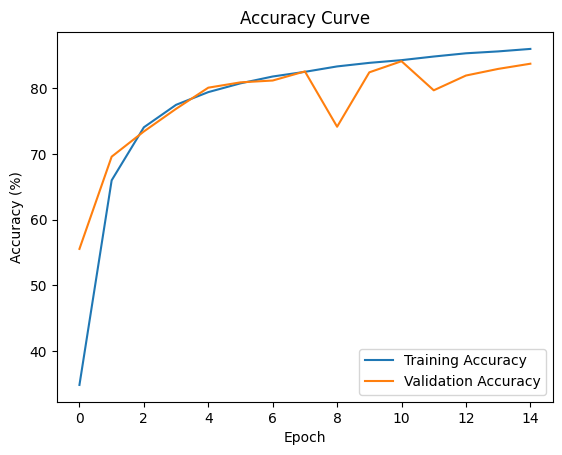

In [73]:
# YOUR CODE HERE

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.title('Accuracy Curve')
plt.show()

### 6.3 Confusion Matrix (5 Marks)

Using `sklearn.metrics`:
1. Compute the confusion matrix on test predictions.
2. Display it as a heatmap using `ConfusionMatrixDisplay` with `class_names` as labels.
3. Title: "StyleAI Fashion Classifier — Test Confusion Matrix"

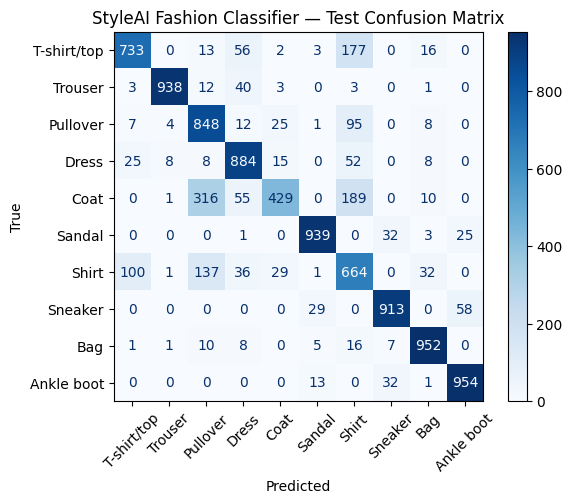

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# YOUR CODE HERE

cm = confusion_matrix(all_labels, all_preds)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
display.plot(xticks_rotation=45, cmap='Blues')

plt.title('StyleAI Fashion Classifier — Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()

### 6.4 Classification Report (5 Marks)

Print the `classification_report` from sklearn using `target_names=class_names`.

In [75]:
from sklearn.metrics import classification_report

# YOUR CODE HERE
print(classification_report(all_labels, all_preds, target_names=class_names))


              precision    recall  f1-score   support

 T-shirt/top       0.84      0.73      0.78      1000
     Trouser       0.98      0.94      0.96      1000
    Pullover       0.63      0.85      0.72      1000
       Dress       0.81      0.88      0.85      1000
        Coat       0.85      0.43      0.57      1000
      Sandal       0.95      0.94      0.94      1000
       Shirt       0.56      0.66      0.60      1000
     Sneaker       0.93      0.91      0.92      1000
         Bag       0.92      0.95      0.94      1000
  Ankle boot       0.92      0.95      0.94      1000

    accuracy                           0.83     10000
   macro avg       0.84      0.83      0.82     10000
weighted avg       0.84      0.83      0.82     10000



### 6.5 Written Analysis (5 Marks)

In the markdown cell below, answer:
1. Which two classes are **most often confused** with each other? Look at the confusion matrix and explain **why** (think about visual similarity).
2. Is the model **overfitting or underfitting**? How can you tell from the learning curves?

*Double-click here to write your analysis*

**Your Analysis:**

1. The classes most often confused are Shirt and T-shirt/top. These classes have similar upper-body shapes, sleeves, necklines, and grayscale patterns. Pullover and Coat can also be confused because they have similar shapes. Footwear and bag classes are easier to recognize because their silhouettes are more different.

2. The model is learning well because both training and validation loss decrease and both accuracies increase. There is a small difference between training and validation accuracy, so there is some mild overfitting, but the curves do not show severe overfitting. Severe overfitting would happen if training loss kept decreasing while validation loss increased and the training accuracy became much higher than validation accuracy.

